Variables temporelles:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("data/dataset_jour.csv", index_col="DATE_TIME", parse_dates=True)

# Variables temporelles brutes
df["heure"] = df.index.hour
df["minute"] = df.index.minute
df["heure_decimale"] = df["heure"] + df["minute"] / 60
df["jour_annee"] = df.index.dayofyear

df.head()

,AC_POWER_TOTAL,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,heure,minute,heure_decimale,jour_annee
DATE_TIME,,,,,,,,
2020-05-15 06:15:00,593.338690,24.011635,22.353459,0.022282,6,15,6.25,136
2020-05-15 06:30:00,1480.194643,23.976731,22.893282,0.049410,6,30,6.50,136
2020-05-15 06:45:00,2790.448214,24.218990,24.442444,0.095394,6,45,6.75,136
2020-05-15 07:00:00,4052.662143,24.537398,27.185653,0.141940,7,0,7.00,136
2020-05-15 07:15:00,4368.722619,24.815960,28.888478,0.154713,7,15,7.25,136


Encodage cyclique:

In [2]:
# L'heure est cyclique : 23h59 est proche de 00h01
df["heure_sin"] = np.sin(2 * np.pi * df["heure_decimale"] / 24)
df["heure_cos"] = np.cos(2 * np.pi * df["heure_decimale"] / 24)

# Idem pour le jour de l'année
df["jour_sin"] = np.sin(2 * np.pi * df["jour_annee"] / 365)
df["jour_cos"] = np.cos(2 * np.pi * df["jour_annee"] / 365)

Visualiser l’effet:

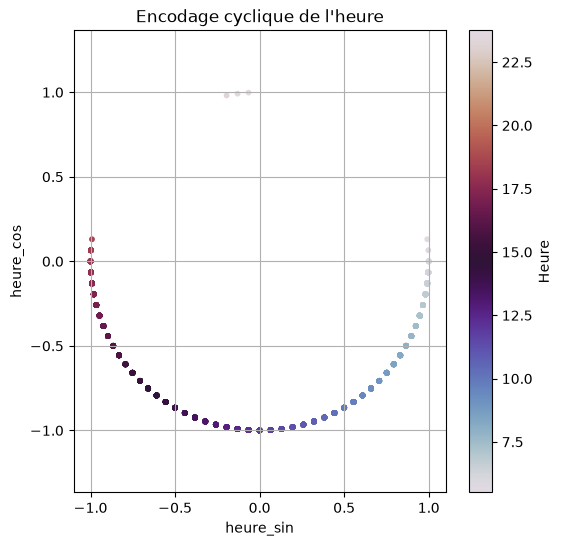

In [3]:
plt.figure(figsize=(6, 6))
plt.scatter(df["heure_sin"], df["heure_cos"], c=df["heure_decimale"], cmap="twilight", s=10)
plt.colorbar(label="Heure")
plt.xlabel("heure_sin")
plt.ylabel("heure_cos")
plt.title("Encodage cyclique de l'heure")
plt.axis("equal")
plt.grid(True)
plt.show()

**Pourquoi un encodage cyclique ?** Fournie telle quelle, l'heure est une
variable numérique où 23 et 0 sont séparés par 23 unités, alors qu'ils ne
sont distants que d'une heure dans la réalité. Un modèle apprendrait donc
une discontinuité artificielle à minuit.

**Principe.** L'heure est projetée sur un cercle unité via deux coordonnées,
`heure_sin` et `heure_cos`. Deux instants proches dans le temps se
retrouvent proches dans ce plan, minuit inclus.

**Lecture du graphique.** L'arc décrit la plage diurne conservée après
filtrage (environ 5 h à 18 h) : le matin à droite, midi en bas, le soir à
gauche. Les quelques points isolés en haut du cercle correspondent aux
mesures résiduelles de 23 h — leur position à l'opposé de l'arc confirme que
l'encodage respecte bien la continuité temporelle.

Le même encodage est appliqué au jour de l'année (`jour_sin`, `jour_cos`)
pour représenter la saisonnalité.

Localisation de la centrale:

In [4]:
import pvlib

# Centrale en Inde (dataset Kaggle) — coordonnées approximatives
latitude = 22.0
longitude = 78.0
fuseau = "Asia/Kolkata"

site = pvlib.location.Location(latitude, longitude, tz=fuseau)

Calculer la position solaire:

In [5]:
# Les horodatages sont en heure locale indienne
index_tz = df.index.tz_localize(fuseau)

solaire = site.get_solarposition(index_tz)

df["elevation_soleil"] = solaire["elevation"].values
df["azimut_soleil"] = solaire["azimuth"].values
df["zenith_soleil"] = solaire["zenith"].values

df[["heure_decimale", "elevation_soleil", "azimut_soleil"]].head()

,heure_decimale,elevation_soleil,azimut_soleil
DATE_TIME,,,
2020-05-15 06:15:00,6.25,7.120492,72.413265
2020-05-15 06:30:00,6.50,10.446997,73.659302
2020-05-15 06:45:00,6.75,13.794356,74.859474
2020-05-15 07:00:00,7.00,17.160397,76.020122
2020-05-15 07:15:00,7.25,20.543182,77.147294


Irradiance ciel clair:

In [6]:
ciel_clair = site.get_clearsky(index_tz)

df["ghi_ciel_clair"] = ciel_clair["ghi"].values  # Global Horizontal Irradiance

L’indice de ciel clair:

In [7]:
# Ratio entre mesuré et théorique : 1 = ciel dégagé, 0 = couvert total
df["indice_ciel_clair"] = df["IRRADIATION"] * 1000 / df["ghi_ciel_clair"]
df["indice_ciel_clair"] = df["indice_ciel_clair"].clip(0, 1.2)

print(df["indice_ciel_clair"].describe())

count    1650.000000
mean        0.670000
std         0.230532
min         0.080379
25%         0.500329
50%         0.677984
75%         0.855803
max         1.200000
Name: indice_ciel_clair, dtype: float64


Vérification visuelle:

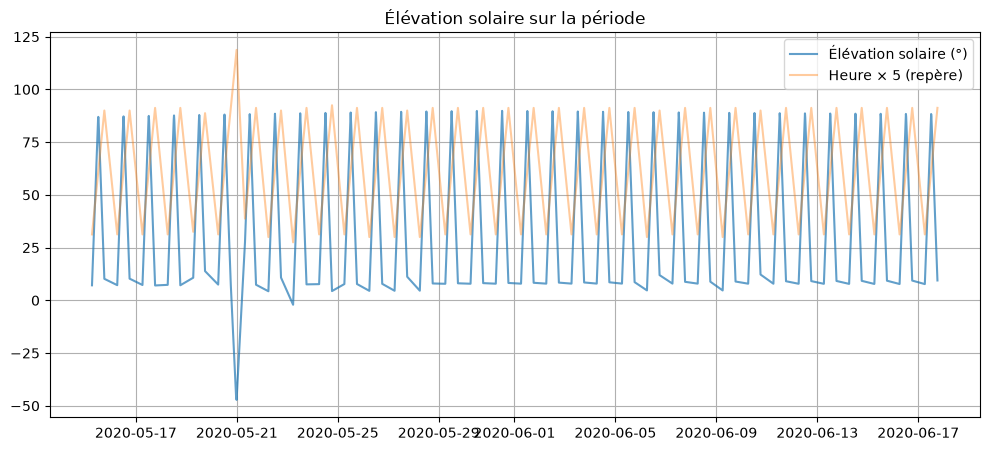

In [8]:
plt.figure(figsize=(12, 5))
plt.plot(df.index, df["elevation_soleil"], label="Élévation solaire (°)", alpha=0.7)
plt.plot(df.index, df["heure_decimale"] * 5, label="Heure × 5 (repère)", alpha=0.4)
plt.legend()
plt.title("Élévation solaire sur la période")
plt.grid(True)
plt.show()

In [9]:
print("Points à 1.2 :", (df["indice_ciel_clair"] >= 1.19).sum())

Points à 1.2 : 11


variables retardées et moyennes glissantes:

In [10]:
# Production passée (persistance locale)
for lag in [1, 2, 4, 96]:
    df[f"prod_lag_{lag}"] = df["AC_POWER_TOTAL"].shift(lag)

# Irradiance passée
for lag in [1, 2, 4]:
    df[f"irr_lag_{lag}"] = df["IRRADIATION"].shift(lag)

# Moyennes glissantes
df["prod_moy_1h"] = df["AC_POWER_TOTAL"].rolling(4).mean()
df["irr_moy_1h"] = df["IRRADIATION"].rolling(4).mean()
df["irr_std_1h"] = df["IRRADIATION"].rolling(4).std()

In [11]:
print("NaN créés par les lags :")
print(df[["prod_lag_1", "prod_lag_96", "prod_moy_1h", "irr_std_1h"]].isna().sum())

NaN créés par les lags :
prod_lag_1      1
prod_lag_96    96
prod_moy_1h     3
irr_std_1h      3
dtype: int64


In [12]:
test = df[["AC_POWER_TOTAL", "prod_lag_96"]].copy()
test["ecart_temps"] = test.index.to_series().diff(96)
print(test["ecart_temps"].describe())

count                      1554
mean     1 days 23:28:29.073359
std      0 days 03:14:57.149697
min             1 days 11:30:00
25%             1 days 23:15:00
50%             1 days 23:30:00
75%             1 days 23:45:00
max             2 days 15:45:00
Name: ecart_temps, dtype: object


In [13]:
# Supprimer la version fausse
df = df.drop(columns=["prod_lag_96"])

# Aller chercher la valeur exactement 24h avant
serie = df["AC_POWER_TOTAL"]
df["prod_veille"] = serie.reindex(df.index - pd.Timedelta("24h")).values
df["irr_veille"] = df["IRRADIATION"].reindex(df.index - pd.Timedelta("24h")).values

print("NaN prod_veille :", df["prod_veille"].isna().sum())

NaN prod_veille : 86


In [14]:
verif = df.index.to_series() - (df.index.to_series() - pd.Timedelta("24h"))
print(df[["AC_POWER_TOTAL", "prod_veille"]].head(100).tail(10))

                     AC_POWER_TOTAL  prod_veille
DATE_TIME                                       
2020-05-16 16:45:00     4775.560714  7643.759524
2020-05-16 17:00:00     4240.298214  4894.992857
2020-05-16 17:15:00     3448.071428  4875.005357
2020-05-16 17:30:00     2516.755357  2558.016667
2020-05-16 17:45:00     1603.101786  1102.005357
2020-05-16 18:00:00      833.828571   628.376786
2020-05-17 06:15:00      259.157143   722.450000
2020-05-17 06:30:00      963.414286  1505.285714
2020-05-17 06:45:00     1883.044643  2414.701786
2020-05-17 07:00:00     3034.264286  3337.728571


Assemblage et vérification du jeu final:

In [15]:
# Liste des variables explicatives
features = [
    "IRRADIATION", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE",
    "heure_sin", "heure_cos", "jour_sin", "jour_cos",
    "elevation_soleil", "azimut_soleil", "ghi_ciel_clair", "indice_ciel_clair",
    "prod_lag_1", "prod_lag_2", "prod_lag_4",
    "irr_lag_1", "irr_lag_2", "irr_lag_4",
    "prod_moy_1h", "irr_moy_1h", "irr_std_1h",
    "prod_veille", "irr_veille"
]

cible = "AC_POWER_TOTAL"

# Retirer les lignes incomplètes
final = df[features + [cible]].dropna()
print("Lignes :", len(final), "| Variables :", len(features))

Lignes : 1564 | Variables : 22


Vérifier les corrélations avec la cible:

In [16]:
corr_cible = final.corr()[cible].drop(cible).sort_values(ascending=False)
print(corr_cible)

IRRADIATION            0.991169
prod_moy_1h            0.933712
irr_moy_1h             0.927230
MODULE_TEMPERATURE     0.920483
prod_lag_1             0.908712
irr_lag_1              0.894536
ghi_ciel_clair         0.864996
elevation_soleil       0.847017
prod_lag_2             0.845643
irr_lag_2              0.832706
prod_veille            0.770054
irr_veille             0.746658
prod_lag_4             0.730575
irr_lag_4              0.723170
indice_ciel_clair      0.700656
AMBIENT_TEMPERATURE    0.544552
irr_std_1h             0.352918
jour_sin               0.079482
jour_cos               0.068107
heure_sin              0.004798
azimut_soleil         -0.051207
heure_cos             -0.860289
Name: AC_POWER_TOTAL, dtype: float64


Détecter les redondances:

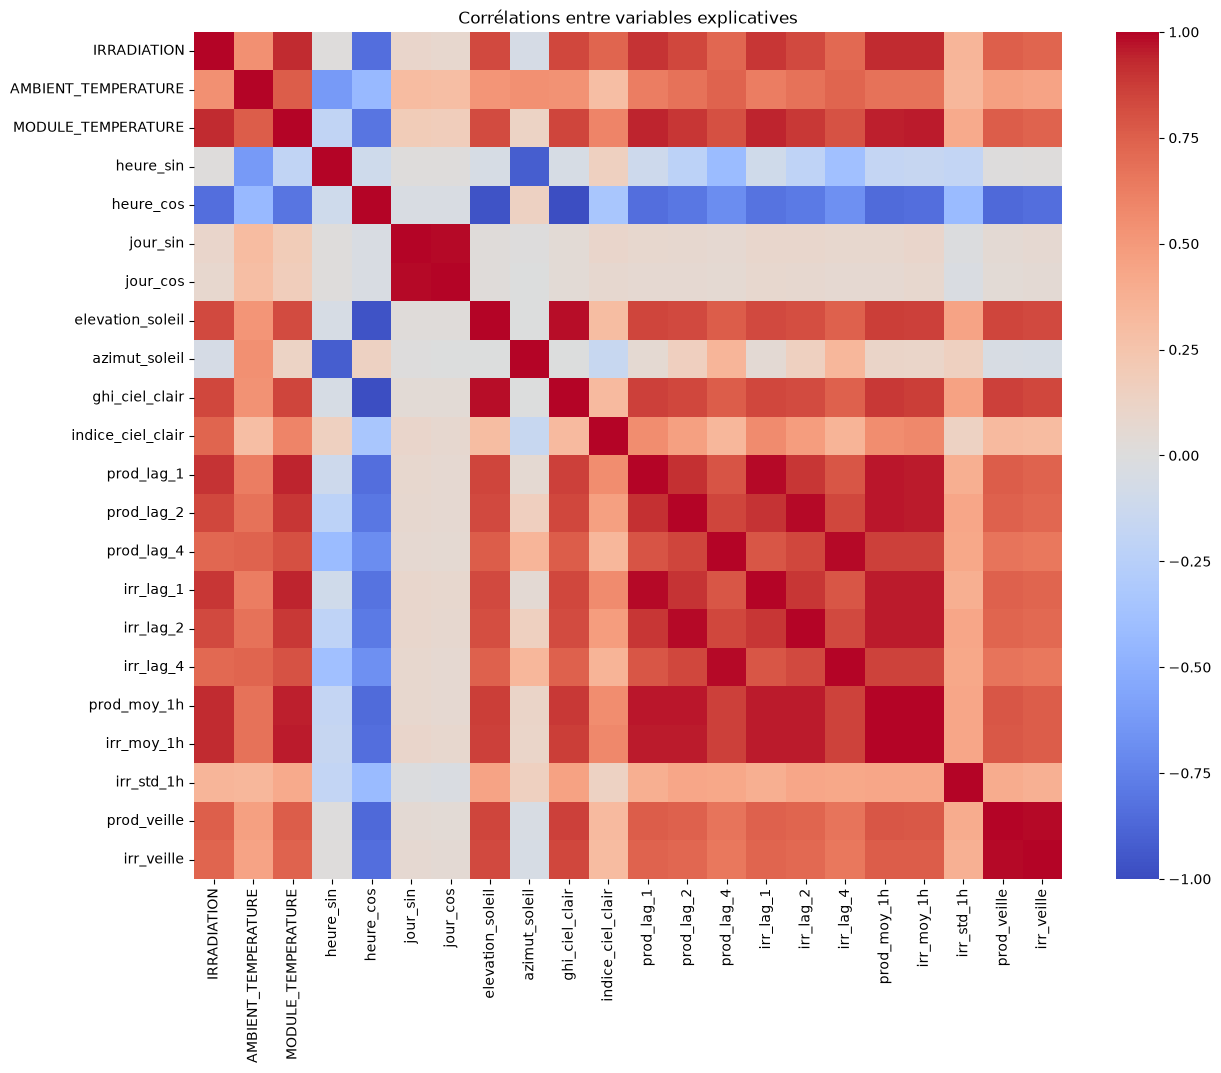

In [17]:
import seaborn as sns
plt.figure(figsize=(14, 11))
sns.heatmap(final[features].corr(), cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Corrélations entre variables explicatives")
plt.show()

In [18]:
features = [f for f in features if f not in ["jour_sin", "jour_cos"]]
final = df[features + [cible]].dropna()
print("Lignes :", len(final), "| Variables :", len(features))

Lignes : 1564 | Variables : 20


In [19]:
final.to_csv("data/dataset_ml.csv")
print(final.columns.tolist())

['IRRADIATION', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'heure_sin', 'heure_cos', 'elevation_soleil', 'azimut_soleil', 'ghi_ciel_clair', 'indice_ciel_clair', 'prod_lag_1', 'prod_lag_2', 'prod_lag_4', 'irr_lag_1', 'irr_lag_2', 'irr_lag_4', 'prod_moy_1h', 'irr_moy_1h', 'irr_std_1h', 'prod_veille', 'irr_veille', 'AC_POWER_TOTAL']
